# **Seq2Seq + Attention 실습**

기존 영어 → 한국어 Seq2Seq 모델에 Attention을 추가하여, Decoder가 출력할 때마다 입력 문장의 각 부분을 다시 참고하도록 만들어보자.



간단한 영어 문장을 한국어로 번역한다.

예) `I went to school yesterday` →`나는 어제 학교에 갔다`

기존 Seq2Seq과 달리, 이번에는 Decoder가 단어를 하나 만들 때마다 **Encoder의 모든 출력과 관련도를 계산**한다.


In [5]:
import torch
import torch.nn as nn
import gradio
import fastmcp
import openai
import requests
import dotenv

print("모든 패키지 import 성공!")
print("PyTorch:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())

c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


모든 패키지 import 성공!
PyTorch: 2.14.1+cu130
CUDA 사용 가능: True


In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(1)

BOS = 1
EOS = 2

ModuleNotFoundError: No module named 'gradio'

## **1. 학습 데이터 만들기**

영어 문장과 한국어 문장을 간단한 규칙으로 여러 개 생성한다.

일부 조합은 학습에서 제외한 뒤 마지막에 번역 결과를 확인한다.


In [2]:
subjects = {
    "i": "나는",
    "you": "너는",
    "he": "그는",
    "she": "그녀는"
}

places = {
    "school": "학교에",
    "library": "도서관에",
    "park": "공원에",
    "museum": "박물관에"
}

times = {
    "yesterday": "어제",
    "today": "오늘",
    "morning": "아침에"
}

test_cases = {
    ("i", "school", "yesterday"),
    ("you", "library", "today"),
    ("he", "park", "morning"),
    ("she", "museum", "yesterday")
}

train_pairs = []
test_pairs = []

for eng_sub, kor_sub in subjects.items():
    for eng_place, kor_place in places.items():
        for eng_time, kor_time in times.items():

            eng = f"{eng_sub} went to {eng_place} {eng_time}"
            kor = f"{kor_sub} {kor_time} {kor_place} 갔다"

            if (eng_sub, eng_place, eng_time) in test_cases:
                test_pairs.append((eng, kor))
            else:
                train_pairs.append((eng, kor))

print("학습 데이터 :", len(train_pairs))
print("테스트 데이터 :", len(test_pairs))
print(train_pairs[0])

학습 데이터 : 44
테스트 데이터 : 4
('i went to school today', '나는 오늘 학교에 갔다')


## **2. 단어를 숫자로 변환하기**

`nn.Embedding`에 넣기 위해 영어와 한국어 단어를 각각 정수 index로 변환한다.


In [3]:
all_pairs = train_pairs + test_pairs
eng_words = sorted({ word for eng, _ in all_pairs for word in eng.split() })
kor_words = sorted({ word for _, kor in all_pairs for word in kor.split() })
eng2idx = { word: i + 3 for i, word in enumerate(eng_words) }
kor2idx = { word: i + 3 for i, word in enumerate(kor_words) }
idx2kor = { idx: word for word, idx in kor2idx.items() }
eng_vocab_size = len(eng2idx) + 3
kor_vocab_size = len(kor2idx) + 3

In [4]:
X = torch.tensor([[eng2idx[word] for word in eng.split()] for eng, _ in train_pairs ])
y = torch.tensor([[kor2idx[word] for word in kor.split()] + [EOS] for _, kor in train_pairs])

print("X :", X.shape)
print("y :", y.shape)
print("영어 :", train_pairs[0][0])
print("한국어 :", train_pairs[0][1])

X : torch.Size([44, 5])
y : torch.Size([44, 5])
영어 : i went to school today
한국어 : 나는 오늘 학교에 갔다


## **3. Encoder 생성하기**

기존 Seq2Seq에서는 마지막 상태만 Decoder에 전달했다.

Attention에서는 Decoder가 입력의 각 부분을 다시 볼 수 있도록 **모든 시점의 Encoder 출력(`outputs`)도 함께 남겨둔다.**


In [5]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embedding_size, hidden_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_size
        )

        self.lstm = nn.LSTM(
            embedding_size,
            hidden_size,
            batch_first=True
        )

    def forward(self, x):
        x = self.embedding(x)
        outputs, (hidden, cell) = self.lstm(x)
        return outputs, hidden, cell


## **4. Attention**

1. 현재 Decoder 상태와 Encoder의 각 출력을 비교한다.
2. `Softmax`로 각 입력을 얼마나 참고할지 계산한다.
3. 중요도가 높은 입력은 많이, 낮은 입력은 적게 반영하여 `context`를 만든다.

여기서는 가장 간단한 **Dot Product Attention**을 사용한다.

다음 Attention 구조를 읽고 이해해보자.

In [6]:
# unsqueeze(n) : n위치에 1인 차원 추가
# squeeze(n) : n인 위치에 1인 차원 제거

class Attention(nn.Module):
    def forward(self, hidden, encoder_outputs):

        query = hidden[-1]

        # bmm : batch matrix multiplication : batch 별 행렬곱
        scores = torch.bmm(
            encoder_outputs,
            query.unsqueeze(2)
        ).squeeze(2)

        # softmax
        weights = torch.softmax(
            scores,
            dim=1
        )

        context = torch.bmm(
            weights.unsqueeze(1),
            encoder_outputs
        ).squeeze(1)

        return context, weights

## **5. Decoder + Attention**

Decoder는 단어를 하나 예측할 때마다 Attention을 다시 계산한다.

`이전 Token + 현재 Attention 정보 → LSTM → 다음 한국어 Token 예측`

다음 Decoder 구조를 읽고 이해해보자.

In [7]:
class AttentionDecoder(nn.Module):
    def __init__(self, vocab_size, embedding_size, hidden_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_size
        )

        self.attention = Attention() # 여기서 attention을 확인한다.

        self.lstm = nn.LSTM(
            embedding_size + hidden_size,
            hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size * 2,
            vocab_size
        )

    def forward(self, x, hidden, cell, encoder_outputs):

        x = self.embedding(x)

        context, weights = self.attention(
            hidden,
            encoder_outputs
        )

        lstm_input = torch.cat(
            [x, context],
            dim=1
        ).unsqueeze(1)

        output, (hidden, cell) = self.lstm(
            lstm_input,
            (hidden, cell)
        )

        output = output.squeeze(1)

        pred = self.fc(
            torch.cat(
                [output, context],
                dim=1
            )
        )
        return pred, hidden, cell, weights


## **6. 모델 생성하기**


In [8]:
embedding_size = 16
hidden_size = 64

encoder = Encoder(
    eng_vocab_size,
    embedding_size,
    hidden_size
)

decoder = AttentionDecoder(
    kor_vocab_size,
    embedding_size,
    hidden_size
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    list(encoder.parameters()) +
    list(decoder.parameters()),
    lr=0.001
)


## **7, 모델 학습**

기존 Seq2Seq과 학습 방식은 거의 같다.

차이는 Decoder가 **매 출력 시점마다 Attention을 계산한다는 것**이다.


In [9]:
epochs = 500
teacher_forcing_ratio = 0.5

encoder.train()
decoder.train()

for epoch in range(epochs):
    optimizer.zero_grad()

    encoder_outputs, hidden, cell = encoder(X)

    decoder_input = torch.full(
        (len(X),),
        BOS,
        dtype=torch.long
    )

    loss = 0

    for t in range(y.size(1)):
        pred, hidden, cell, weights = decoder(
            decoder_input,
            hidden,
            cell,
            encoder_outputs
        )

        loss += criterion(
            pred,
            y[:, t]
        )

        use_teacher = (
            torch.rand(1).item() < teacher_forcing_ratio
        )

        if use_teacher:
            decoder_input = y[:, t]
        else:
            decoder_input = pred.argmax(dim=1)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss {loss.item() / y.size(1):.4f}"
        )


Epoch 100 | Loss 0.3802
Epoch 200 | Loss 0.0313
Epoch 300 | Loss 0.0120
Epoch 400 | Loss 0.0067
Epoch 500 | Loss 0.0043


## **8. 학습하지 않은 문장 번역하기**

Teacher Forcing 없이 모델이 직접 다음 Token을 예측한다.


In [10]:
encoder.eval()
decoder.eval()

with torch.no_grad():

    for eng, answer in test_pairs:

        x = torch.tensor([[
            eng2idx[word]
            for word in eng.split()
        ]])

        encoder_outputs, hidden, cell = encoder(x)

        decoder_input = torch.tensor([BOS])

        result = []

        for _ in range(6):
            pred, hidden, cell, weights = decoder(
                decoder_input,
                hidden,
                cell,
                encoder_outputs
            )

            decoder_input = pred.argmax(dim=1)

            token = decoder_input.item()

            if token == EOS:
                break

            result.append(
                idx2kor[token]
            )

        print("영어 :", eng)
        print("정답 :", answer)
        print("예측 :", " ".join(result))
        print()


영어 : i went to school yesterday
정답 : 나는 어제 학교에 갔다
예측 : 나는 어제 학교에 갔다

영어 : you went to library today
정답 : 너는 오늘 도서관에 갔다
예측 : 너는 오늘 도서관에 갔다

영어 : he went to park morning
정답 : 그는 아침에 공원에 갔다
예측 : 그는 아침에 공원에 갔다

영어 : she went to museum yesterday
정답 : 그녀는 어제 박물관에 갔다
예측 : 그녀는 어제 박물관에 갔다



## **9. Attention Weight 확인하기**

한 문장을 번역하면서, 각 한국어 단어를 만들 때 영어 입력의 어느 부분을 얼마나 참고했는지 확인한다.

숫자가 클수록 해당 입력을 더 많이 참고했다는 의미이다.


In [11]:
eng = "you went to park yesterday"

x = torch.tensor([[eng2idx[word] for word in eng.split()]])

input_words = eng.split()
encoder_outputs, hidden, cell = encoder(x)
decoder_input = torch.tensor([BOS])

print("입력 :", input_words)

입력 : ['you', 'went', 'to', 'park', 'yesterday']


In [12]:
with torch.no_grad():
    for _ in range(6):

        pred, hidden, cell, weights = decoder(
            decoder_input,
            hidden,
            cell,
            encoder_outputs
        )

        decoder_input = pred.argmax(dim=1)
        token = decoder_input.item()

        if token == EOS:
            break

        output_word = idx2kor[token]
        print("출력 :", output_word)

        for word, weight in zip(input_words, weights[0].tolist()):
            print(f"  {word:10s} : {weight:.3f}")
        print()


출력 : 너는
  you        : 0.000
  went       : 0.000
  to         : 0.000
  park       : 0.001
  yesterday  : 0.999

출력 : 어제
  you        : 0.000
  went       : 0.000
  to         : 0.000
  park       : 0.014
  yesterday  : 0.986

출력 : 공원에
  you        : 0.000
  went       : 0.000
  to         : 0.005
  park       : 0.993
  yesterday  : 0.002

출력 : 갔다
  you        : 0.003
  went       : 0.005
  to         : 0.946
  park       : 0.046
  yesterday  : 0.000



# **Attention Heatmap**

Attention Weight를 표 형태로 모으면, **각 한국어 출력 단어가 영어 입력의 어느 단어를 많이 참고했는지** 한눈에 확인할 수 있다.

* 가로축 : 영어 입력 단어
* 세로축 : 한국어 출력 단어
* 값이 클수록 해당 입력 단어를 더 많이 참고했다는 의미


In [13]:
# 한글 설치
!pip install -q koreanize-matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import koreanize_matplotlib
plt.rcParams['axes.unicode_minus'] = False


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## **1.Attention Weight 저장하기**

번역 과정에서 매 출력 시점의 Attention Weight를 저장한다.


In [14]:
eng = "i went to school yesterday"

x = torch.tensor([[
    eng2idx[word]
    for word in eng.split()
]])

input_words = eng.split()
encoder_outputs, hidden, cell = encoder(x)
decoder_input = torch.tensor([BOS])
output_words = []
attention_weights = []
encoder.eval()
decoder.eval()


AttentionDecoder(
  (embedding): Embedding(15, 16)
  (attention): Attention()
  (lstm): LSTM(80, 64, batch_first=True)
  (fc): Linear(in_features=128, out_features=15, bias=True)
)

In [15]:
with torch.no_grad():
    for _ in range(6):

        pred, hidden, cell, weights = decoder(
            decoder_input,
            hidden,
            cell,
            encoder_outputs
        )

        decoder_input = pred.argmax(dim=1)
        token = decoder_input.item()

        if token == EOS:
            break

        output_words.append(idx2kor[token])
        attention_weights.append(weights[0].cpu())

attention_matrix = torch.stack(attention_weights).numpy()

print("입력 :", input_words)
print("출력 :", output_words)
print("Attention shape :", attention_matrix.shape)

입력 : ['i', 'went', 'to', 'school', 'yesterday']
출력 : ['나는', '어제', '학교에', '갔다']
Attention shape : (4, 5)


## **2. Attention 시각화하기**

attention_matrix를 활용하여 heatmap으로 시각화해보자.
- 각 칸의 숫자는 Attention Weight이다.
- 값이 큰 칸일수록 Decoder가 해당 출력 단어를 만들 때 그 입력 단어를 더 많이 참고했다는 뜻이다.


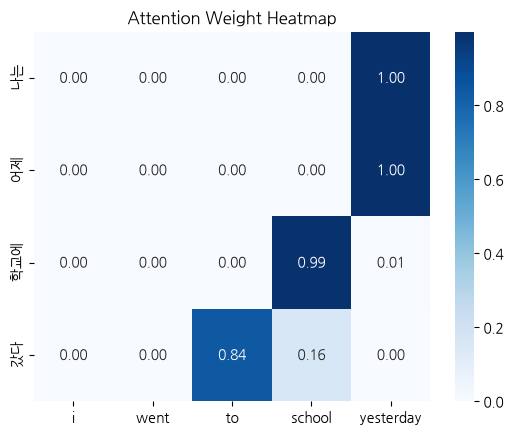

In [16]:
plt.title("Attention Weight Heatmap")
plt.xlabel("English labels")
plt.ylabel("Korean labels")
sns.heatmap(attention_matrix, annot=True, fmt=".2f", cmap="Blues", xticklabels=input_words, yticklabels=output_words)
plt.show()